# Búsqueda y selección de modelos

Este notebook desarrolla el objetivo específico 2 del proyecto: desarrollar y comparar modelos de estimación ordinal del SII basados en indicadores físicos y demográficos, frente a un modelo de referencia, mediante validación cruzada estratificada y el QWK. Se comparan cuatro algoritmos —un modelo lineal regularizado, una SVM con kernel radial, un bosque aleatorio y gradient boosting— en tres formulaciones del SII —clasificación multiclase, descomposición ordinal de Frank y Hall y regresión con umbrales—, con la estrategia de tratamiento de los faltantes y la ponderación de los niveles como hiperparámetros de la validación interna.

El análisis exploratorio (`01_eda.ipynb`) definió el conjunto analítico: los participantes con SII registrado, las reglas de limpieza de valores inválidos, las variables excluidas por cobertura o redundancia, el resumen de la actigrafía y cuatro conjuntos anidados de predictores (referencia, principal sin actigrafía, principal y complementario). Los experimentos iniciales (`02_experimentos_iniciales.ipynb`) evaluaron dos configuraciones fijas en la formulación multiclase: no mostraron evidencia de mejora del conjunto principal frente a la referencia (H2) ni de la actigrafía (H3), y las dos configuraciones trataron el nivel severo de forma opuesta. Por eso la búsqueda completa amplía los algoritmos, las formulaciones y la ponderación, y vuelve a evaluar H2 y H3 con la configuración que resulte seleccionada.

El notebook se organiza así:

1. Datos y conjuntos de variables.
2. Diseño de la búsqueda.
3. Estimación del costo de cómputo.
4. Búsqueda completa.
5. Hiperparámetros elegidos y revisión de los bordes de la grilla.
6. Selección de la configuración.
7. Desempeño por nivel de la configuración seleccionada.
8. H2 y H3 con la configuración seleccionada.
9. Comparación en la subpoblación con actigrafía.
10. Configuración guardada y conclusiones.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.dummy import DummyClassifier
from threadpoolctl import threadpool_info

from piu_severity.config import FIGURES_DIR, INTERIM_DATA_DIR, RANDOM_SEED
from piu_severity.data.clean import clean_values
from piu_severity.data.load import list_actigraphy_ids, load_train
from piu_severity.evaluation.metrics import SII_LEVELS, as_levels
from piu_severity.evaluation.persistence import (
    CACHE_VERSION,
    directory_size,
    run_configurations_cached,
)
from piu_severity.evaluation.selection import (
    EDGE_RULE_MIN_FOLDS,
    HOLM_FAMILIES,
    MINIMUM_RELEVANT_QWK_DIFFERENCE,
    SELECTION_ALPHA,
    UNDERESTIMATION_TIE_TOLERANCE,
    apply_selection_rule,
    chosen_value_counts,
    compare_with_best,
    edge_review,
    grid_extension,
    most_frequent_value,
    parameter_short_name,
    selected_configuration,
)
from piu_severity.evaluation.validation import (
    N_INNER_SPLITS,
    N_OUTER_REPEATS,
    N_OUTER_SPLITS,
    aggregate_repeats,
    outer_splits,
    run_nested_cv,
    split_level_counts,
    summarize_by_repeat,
)
from piu_severity.features.actigraphy import (
    load_actigraphy_summary,
    usable_actigraphy_mask,
)
from piu_severity.features.build import build_analytic_dataset
from piu_severity.features.groups import (
    TARGET_COLUMN,
    experiment_feature_sets,
    is_excluded,
    is_instrument_season,
)
from piu_severity.models.pipelines import (
    ALGORITHMS,
    BOOSTING_MAX_ITER,
    BOOSTING_N_ITER_NO_CHANGE,
    BOOSTING_VALIDATION_FRACTION,
    CONVERGENCE_WARNING_MAX_SHARE,
    CUT_BOOSTING_RANDOM_CANDIDATES,
    CUT_FOREST_N_ESTIMATORS,
    EXECUTION_POOLS,
    FOREST_CORES_PER_WORKER,
    FOREST_N_ESTIMATORS,
    FORMULATIONS,
    LINEAR_MAX_ITER,
    MAX_CUT_LEVEL,
    MAX_ITER_INCREASE,
    MEMORY_BUDGET_FRACTION,
    MEMORY_SAFETY_FACTOR,
    MODELS_PER_PIPELINE_FIT,
    RESERVED_CORES,
    SEARCH_BUDGET_HOURS,
    available_workers,
    choose_cut_level,
    complexity_key,
    convergence_warning_share,
    cost_ratio,
    make_search_task,
    max_iter_factor_for,
    memory_budget_gb,
    n_candidates,
    n_forest_trees,
    pool_workers,
    project_search_hours,
    search_grid,
    total_memory_gb,
    workers_within_memory,
)
from piu_severity.visualization.figures import save_figure

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# Figuras del notebook y carpetas de los dos cachés. Ambas carpetas están bajo
# data/interim, que git ignora, porque guardan datos transformados y predicciones
# por participante.
FIGURAS = FIGURES_DIR / "03_busqueda_modelos"
CARPETA_NOTEBOOK = INTERIM_DATA_DIR / "03_busqueda_modelos"
# Caché de resultados: un archivo por configuración, conjunto, repetición y partición.
CARPETA_CACHE = CARPETA_NOTEBOOK / "cache"
# Caché de Pipeline(memory=...): evita reajustar el preprocesamiento entre candidatos.
# Incluye la versión del caché porque joblib no detecta cambios en el código propio.
CARPETA_MEMORIA = CARPETA_NOTEBOOK / "pipeline_memory" / f"v{CACHE_VERSION}"

# Con True se recalculan todas las evaluaciones aunque exista un resultado válido.
RECALCULAR = False

# Recursos del equipo en el que se ejecuta el notebook: los procesos en paralelo
# y el presupuesto de memoria se calculan a partir de ellos.
N_NUCLEOS = os.cpu_count()
MEMORIA_TOTAL_GB = total_memory_gb()

NIVELES_SII = {0: "ninguno", 1: "leve", 2: "moderado", 3: "severo"}
NOMBRES_CONJUNTOS = {
    "reference": "referencia",
    "reference_with_actigraphy": "referencia con actigrafía",
    "main_without_actigraphy": "principal sin actigrafía",
    "main": "principal",
    "complementary": "complementario",
}
NOMBRES_ALGORITMOS = {
    "linear": "lineal regularizado",
    "svm": "SVM con kernel radial",
    "random_forest": "bosque aleatorio",
    "gradient_boosting": "gradient boosting",
}
NOMBRES_FORMULACIONES = {
    "threshold_regression": "regresión con umbrales",
    "multiclass": "multiclase",
    "frank_hall": "Frank y Hall",
}
NOMBRES_ESTRATEGIAS = {
    "native": "nativa",
    "simple": "simple con indicadores",
    "iterative": "iterativa",
}
# Las doce configuraciones de la búsqueda, en el orden de complejidad del paquete.
CONFIGURACIONES = [(a, f) for a in ALGORITHMS for f in FORMULATIONS]

## 1. Datos y conjuntos de variables

La búsqueda usa el mismo conjunto analítico de los notebooks anteriores, construido con las funciones del paquete: los participantes con SII registrado, con las reglas de limpieza del análisis exploratorio y el resumen de las series de actigrafía. Antes de modelar, esta sección verifica que el conjunto reproduce las cifras de la Entrega 2 (número de participantes, de casos severos, de predictores por conjunto y de participantes con una serie de actigrafía utilizable), que ningún conjunto incluye las columnas del PCIAT, el identificador o las temporadas de cada instrumento, y construye las particiones externas que comparten todas las configuraciones.

In [3]:
# Participantes con SII y conjunto analítico, con las mismas funciones del paquete
# que usan los notebooks 01 y 02.
train = load_train()
etiquetados = train[train[TARGET_COLUMN].notna()].reset_index(drop=True)
analitico = build_analytic_dataset(
    clean_values(etiquetados), load_actigraphy_summary(list_actigraphy_ids())
)
y = as_levels(analitico[TARGET_COLUMN])
conjuntos = experiment_feature_sets(analitico.columns)

# Cifras de la Entrega 2 que este conjunto debe reproducir.
N_ETIQUETADOS_ENTREGA_2 = 2_736
N_SEVEROS_ENTREGA_2 = 34
N_PREDICTORES_ENTREGA_2 = {
    "reference": 3,
    "main": 36,
    "main_without_actigraphy": 33,
    "complementary": 39,
}
assert len(analitico) == N_ETIQUETADOS_ENTREGA_2
assert analitico["id"].is_unique
assert int((y == 3).sum()) == N_SEVEROS_ENTREGA_2
assert {nombre: len(c) for nombre, c in conjuntos.items()} == N_PREDICTORES_ENTREGA_2

# Ningún conjunto incluye el PCIAT, el identificador ni las temporadas por instrumento,
# y los conjuntos están anidados.
assert not any(
    is_excluded(c) or is_instrument_season(c)
    for columnas in conjuntos.values()
    for c in columnas
)
assert (
    set(conjuntos["reference"])
    <= set(conjuntos["main_without_actigraphy"])
    <= set(conjuntos["main"])
    <= set(conjuntos["complementary"])
)

distribucion_sii = (
    pd.Series(y)
    .map(NIVELES_SII)
    .value_counts()
    .reindex(NIVELES_SII.values())
    .rename_axis("SII")
    .to_frame("participantes")
)
distribucion_sii["%"] = (100 * distribucion_sii["participantes"] / len(y)).round(1)
distribucion_sii

,participantes,%
SII,,
ninguno,1594,58.3
leve,730,26.7
moderado,378,13.8
severo,34,1.2


In [4]:
# Subpoblación con una serie de actigrafía utilizable: la que se analiza aparte en la
# sección 9. Las cifras de la Entrega 2 se verifican aquí porque la búsqueda usa
# a todos los participantes y la ausencia de la serie se trata como un faltante más.
N_ACTIGRAFIA_ENTREGA_2 = 823
N_SEVEROS_ACTIGRAFIA_ENTREGA_2 = 6

con_actigrafia = usable_actigraphy_mask(analitico).to_numpy()
assert int(con_actigrafia.sum()) == N_ACTIGRAFIA_ENTREGA_2
assert int((y[con_actigrafia] == 3).sum()) == N_SEVEROS_ACTIGRAFIA_ENTREGA_2

composicion_conjuntos = pd.DataFrame(
    {
        "predictores": {
            NOMBRES_CONJUNTOS[nombre]: len(columnas)
            for nombre, columnas in conjuntos.items()
        },
        "incluye actigrafía": {
            NOMBRES_CONJUNTOS[nombre]: "sí"
            if any(c.startswith("Actigraphy-") for c in columnas)
            else "no"
            for nombre, columnas in conjuntos.items()
        },
    }
).rename_axis("conjunto")

print(f"Participantes con SII: {len(analitico)}")
print(
    f"Participantes con serie de actigrafía utilizable: {int(con_actigrafia.sum())} "
    f"({100 * con_actigrafia.mean():.1f} %), de ellos "
    f"{int((y[con_actigrafia] == 3).sum())} severos"
)
composicion_conjuntos

Participantes con SII: 2736
Participantes con serie de actigrafía utilizable: 823 (30.1 %), de ellos 6 severos


,predictores,incluye actigrafía
conjunto,,
referencia,3,no
principal,36,sí
principal sin actigrafía,33,no
complementario,39,sí


In [5]:
# Particiones externas: validación cruzada estratificada por SII con cinco particiones,
# repetida cinco veces con la semilla 42 + r en la repetición r. Todas las
# configuraciones y conjuntos se evalúan sobre estas mismas particiones.
particiones = outer_splits(y)
assert len(particiones) == N_OUTER_SPLITS * N_OUTER_REPEATS

casos_por_particion = split_level_counts(particiones, y).rename(columns=NIVELES_SII)
print(
    f"{N_OUTER_REPEATS} repeticiones × {N_OUTER_SPLITS} particiones externas; "
    f"{N_INNER_SPLITS} particiones internas en cada búsqueda"
)
# Rango de casos de cada nivel en las 25 particiones de evaluación.
casos_por_particion.agg(["min", "max"]).rename_axis("casos por partición")

5 repeticiones × 5 particiones externas; 3 particiones internas en cada búsqueda


,ninguno,leve,moderado,severo
casos por partición,,,,
min,318,146,75,6
max,319,146,76,7


### Conclusión

El conjunto analítico reproduce las cifras de la Entrega 2:

- **Participantes y niveles.** Hay 2.736 participantes con SII: 58,3 % en el nivel ninguno, 26,7 % en leve, 13,8 % en moderado y 1,2 % en severo, que son 34 casos.
- **Predictores por conjunto.** La referencia tiene 3, el principal sin actigrafía 33, el principal 36 y el complementario 39.
- **Actigrafía.** 823 participantes (30,1 %) tienen una serie utilizable, y solo 6 de ellos son severos. Por eso la ausencia de la serie se trata en la búsqueda como un faltante más, y la comparación restringida a esa subpoblación se hace aparte, en la sección 9.
- **Exclusiones.** Ningún conjunto incluye columnas del PCIAT, el identificador ni las temporadas por instrumento, y los conjuntos están anidados.

Las 25 particiones externas conservan la proporción de cada nivel: cada partición de evaluación tiene entre 318 y 319 participantes del nivel ninguno, 146 del leve, entre 75 y 76 del moderado y entre 6 y 7 severos. Con tan pocos casos severos, un solo acierto cambia el recall severo de una partición en unos 15 puntos porcentuales. Por eso ese recall se calcula sobre las predicciones acumuladas de cada repetición, que cubren los 34 casos. Todas las configuraciones y conjuntos se evalúan sobre estas mismas particiones, lo que permite compararlos de forma pareada.

## 2. Diseño de la búsqueda

La búsqueda compara doce configuraciones: cuatro algoritmos por tres formulaciones del SII. Cada configuración es una búsqueda interna sobre una grilla que incluye la estrategia de faltantes, la intensidad de la ponderación de los niveles y los hiperparámetros del modelo. Todas las decisiones de esta sección —grillas, recortes por presupuesto, reglas de convergencia y de bordes, diferencia mínima relevante, tolerancia de empate, familias de pruebas y orden de complejidad— quedaron fijadas en el paquete antes de ejecutar la búsqueda, de modo que ninguna depende de sus resultados. Esta sección las reúne a partir del propio código.

In [6]:
def describir_valores(valores: list) -> str:
    """Resume los valores de un hiperparámetro: rango si son muchos, lista si son pocos."""
    numericos = all(isinstance(v, (int, float)) for v in valores)
    if numericos and len(valores) > 4:
        return f"{min(valores):g} a {max(valores):g} ({len(valores)} valores)"
    return ", ".join(
        f"{v:g}" if isinstance(v, (int, float)) else str(v) for v in valores
    )


# Parámetros de la grilla que no son del modelo: estrategia de faltantes y exponente
# de los pesos por nivel.
PARAMETROS_DE_TRATAMIENTO = ("preprocess__strategy", "model__weight_power")

filas = []
for algoritmo, formulacion in CONFIGURACIONES:
    grilla = search_grid(algoritmo, formulacion)
    filas.append(
        {
            "algoritmo": NOMBRES_ALGORITMOS[algoritmo],
            "formulación": NOMBRES_FORMULACIONES[formulacion],
            "estrategias de faltantes": ", ".join(
                NOMBRES_ESTRATEGIAS[e] for e in grilla["preprocess__strategy"]
            ),
            "α": ", ".join(f"{a:g}" for a in grilla["model__weight_power"]),
            # El nombre del hiperparámetro es la última parte de la ruta del pipeline.
            "hiperparámetros del modelo": "; ".join(
                f"{nombre.split('__')[-1]}: {describir_valores(valores)}"
                for nombre, valores in grilla.items()
                if nombre not in PARAMETROS_DE_TRATAMIENTO
            ),
            "candidatos": n_candidates(algoritmo, formulacion),
        }
    )

diseno_busqueda = pd.DataFrame(filas).set_index(["algoritmo", "formulación"])
diseno_busqueda

estrategias de faltantes  \
algoritmo             formulación                                                         
lineal regularizado   regresión con umbrales          simple con indicadores, iterativa   
                      multiclase                      simple con indicadores, iterativa   
                      Frank y Hall                    simple con indicadores, iterativa   
SVM con kernel radial regresión con umbrales          simple con indicadores, iterativa   
                      multiclase                      simple con indicadores, iterativa   
                      Frank y Hall                    simple con indicadores, iterativa   
bosque aleatorio      regresión con umbrales          simple con indicadores, iterativa   
                      multiclase                      simple con indicadores, iterativa   
                      Frank y Hall                    simple con indicadores, iterativa   
gradient boosting     regresión con umbrales  nativa, simple con indicadores, iterativa   
                      multiclase              nativa, simple con indicadores, iterativa   
                      Frank y Hall            nativa, simple con indicadores, iterativa   

                                                   α  \
algoritmo             formulación                      
lineal regularizado   regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   
SVM con kernel radial regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   
bosque aleatorio      regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   
gradient boosting     regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   

                                                                                                                                  hiperparámetros del modelo  \
algoritmo             formulación                                                                                                                              
lineal regularizado   regresión con umbrales                                                             alpha: 0.0001 a 10 (6 valores); l1_ratio: 0, 0.5, 1   
                      multiclase                                                                            C: 0.0001 a 100 (7 valores); l1_ratio: 0, 0.5, 1   
                      Frank y Hall                                                                          C: 0.0001 a 100 (7 valores); l1_ratio: 0, 0.5, 1   
SVM con kernel radial regresión con umbrales                                    C: 0.01 a 1000 (6 valores); gamma: 0.0001 a 1 (5 valores); epsilon: 0.1, 0.5   
                      multiclase                                                                   C: 0.01 a 1000 (6 valores); gamma: 0.0001 a 1 (5 valores)   
                      Frank y Hall                                                                 C: 0.01 a 1000 (6 valores); gamma: 0.0001 a 1 (5 valores)   
bosque aleatorio      regresión con umbrales                                               max_features: sqrt, 0.33, 0.66, 1; min_samples_leaf: 1, 5, 20, 50   
                      multiclase                                                           max_features: sqrt, 0.33, 0.66, 1; min_samples_leaf: 1, 5, 20, 50   
                      Frank y Hall                                                         max_features: sqrt, 0.33, 0.66, 1; min_samples_leaf: 1, 5, 20, 50   
gradient boosting     regresión con umbrales  learning_rate: 0.03, 0.1; max_leaf_nodes: 7, 15, 31; min_samples_leaf: 10, 30, 80; l2_regularization: 0, 1, 10   
                      multiclase              learning_rate: 0.03, 0.1; max_leaf_no

### Decisiones del diseño

**Formulaciones del SII.**
- *Multiclase nominal:* ignora el orden de los niveles y sirve como formulación base.
- *Frank y Hall:* tres clasificadores binarios estiman $P(\text{SII} > k)$ para $k = 0, 1, 2$. Como se entrenan por separado, se aplica el mínimo acumulado sobre $k$ antes de obtener por diferencias la probabilidad de cada nivel, y se asigna el nivel de mayor probabilidad. La SVM no produce probabilidades por sí misma, así que en esta formulación se calibra con una sigmoide ajustada en tres particiones internas estratificadas.
- *Regresión con umbrales:* el SII se estima como variable continua y se discretiza con tres umbrales ordenados que maximizan el QWK. Los umbrales se ajustan sobre predicciones fuera de pliegue obtenidas con tres particiones estratificadas por nivel dentro de los datos de entrenamiento de cada ajuste, de modo que la partición de evaluación no interviene. Como el QWK cambia de forma escalonada con los umbrales, se buscan por coordenadas sobre los cuantiles de las predicciones, desde dos puntos de partida.

**Tratamiento de los faltantes.** La estrategia es un hiperparámetro de la validación interna:
- *nativa:* los faltantes llegan al modelo; solo en gradient boosting, como establece la formulación;
- *simple:* mediana o moda, con un indicador de ausencia por instrumento;
- *iterativa:* imputación multivariada, sin indicadores, para que se distinga de la simple. En los modelos lineales y la SVM, las variables numéricas pasan por Yeo-Johnson antes de imputar, para que los modelos lineales del imputador trabajen sobre escalas menos asimétricas, y se estandarizan después. Los códigos binarios y ordinales imputados se redondean y se recortan al rango observado en el entrenamiento.

En los modelos lineales y la SVM, las ordinales solo se estandarizan, las binarias quedan en 0 y 1 y la temporada de inscripción va con codificación one-hot. Todo se ajusta dentro del `Pipeline`, con los datos de entrenamiento.

**Ponderación de los niveles.** Cada ajuste pondera las observaciones con
$$w_k = \left(\frac{n}{K\, n_k}\right)^{\alpha},$$
donde $n_k$ es la frecuencia del nivel $k$ en los datos de ese ajuste y $K$ el número de niveles presentes. Con $\alpha = 1$ se obtienen los pesos inversamente proporcionales a la frecuencia de la formulación; con $\alpha = 0{,}5$ la ponderación se atenúa. El exponente se elige en la validación interna porque las dos configuraciones de los experimentos iniciales trataron mal el nivel severo con la ponderación completa. En Frank y Hall cada binario pondera sus dos clases, y en la regresión cada observación lleva el peso de su nivel.

**Hiperparámetros y límites fijos.**
- *Modelo lineal:* `l1_ratio` en {0; 0,5; 1} elige el tipo de regularización (ridge, elastic net o lasso) y `C` o `alpha` su intensidad.
- *Logística:* `saga`, con hasta 10.000 iteraciones.
- *Elastic net:* hasta 10.000 iteraciones.
- *Bosque aleatorio:* 500 árboles.
- *Gradient boosting:* parada temprana con hasta 1.000 iteraciones, 20 iteraciones sin mejora y el 15 % de los datos de entrenamiento como validación.
- *Semillas:* todos los componentes con azar llevan semilla fija, incluidos el bosque, la parada temprana, el imputador, los pliegues de la calibración y los de los umbrales.

**Validación.** La validación externa es estratificada, con cinco particiones repetidas cinco veces, y la interna tiene tres particiones estratificadas dentro de cada partición de entrenamiento. El QWK de la validación interna elige el candidato de cada búsqueda. Las particiones externas se ajustan en paralelo y cada búsqueda interna es secuencial.

**Presupuesto de cómputo y recortes.** La búsqueda completa tiene un presupuesto de 10 horas de reloj. Antes de ejecutarla, la sección 3 mide los tiempos de la primera repetición. Con esos tiempos, la regla elige el nivel de recorte más bajo cuya proyección cabe en el presupuesto. Los niveles son acumulativos:
1. $\alpha$ solo en 1 para la SVM;
2. grilla de la SVM reducida a 4 × 4;
3. bosques de 300 árboles;
4. gradient boosting sin `l2_regularization`;
5. gradient boosting con búsqueda aleatoria de 40 candidatos, como último recurso.

La regla usa solo los tiempos medidos y nunca el QWK. Como los tiempos dependen del equipo en el que se ejecuta el notebook, el nivel elegido se reporta junto con los resultados y forma parte de la firma del caché.

**Procesos y memoria.** Los recursos se calculan a partir del equipo en el que se ejecuta el notebook:
- *Procesos por algoritmo:* cada partición externa se ajusta en un proceso. El modelo lineal, la SVM y gradient boosting usan todos los núcleos menos dos. El bosque aleatorio, que guarda cientos de árboles en memoria, usa un proceso por cada tres de esos núcleos.
- *Regla de memoria:* el presupuesto es el 75 % de la memoria física del equipo. Si la memoria máxima medida por proceso en la sección 3, multiplicada por un factor de seguridad de 1,25, no cabe en ese presupuesto, el número de procesos de ese algoritmo se reduce hasta que quepa.
- *Independencia de los resultados:* el número de procesos cambia el tiempo de ejecución, no los resultados, porque cada ajuste tiene semillas fijas.

**Convergencia.** Las advertencias de convergencia se cuentan en cada ajuste y se separan entre las del modelo y las del imputador. Si en la primera repetición más del 5 % de los ajustes de una configuración no converge, sus límites de iteraciones se multiplican por 5 antes de la búsqueda completa.

**Regla de selección.**
1. Se identifica la configuración con mayor QWK medio.
2. Entre las configuraciones cuya diferencia frente a ella no es significativa según la prueba t corregida de Nadeau y Bengio (unilateral, $\alpha = 0{,}05$), se selecciona la de menor tasa de subestimación. Dos tasas que difieren en menos de 0,01 se consideran empatadas.
3. Si persiste el empate, se elige la de menor complejidad.

El orden de complejidad se refiere a la capacidad del modelo final, no a su interpretabilidad ni al costo de ajustarlo:
- *Algoritmo* (lineal < SVM < bosque aleatorio < gradient boosting): el modelo lineal es una función lineal de los predictores; la SVM es una sola frontera suave controlada por dos hiperparámetros, aunque sea la menos interpretable; el bosque promedia cientos de árboles independientes; gradient boosting encadena árboles que corrigen los errores de los anteriores.
- *Formulación* (regresión con umbrales < multiclase < Frank y Hall): la regresión ajusta una sola función y tres escalares, pues su validación interna es parte del ajuste y no del modelo; la multiclase ajusta una función por nivel; Frank y Hall ajusta tres modelos independientes.
- *Estrategia de faltantes* (nativa = simple < iterativa): la iterativa agrega un modelo de imputación por variable. Como la estrategia se elige en cada partición, se usa la más frecuente de la configuración.

Como la selección usa las mismas particiones con las que se reporta el desempeño, el QWK de la configuración seleccionada tiene un sesgo optimista, que se declara al reportarlo.

**Revisión de los bordes de la grilla.** Si un hiperparámetro elige un extremo de su grilla en al menos 5 de las 25 particiones, la grilla se amplía un paso en esa dirección y esa configuración se repite y se guarda aparte, como máximo una vez. La regla usa solo los hiperparámetros elegidos en la validación interna.

**Diferencia mínima relevante y familias de pruebas.** Para afirmar que un conjunto de variables no aporta de forma relevante, la diferencia de QWK se contrasta contra $\Delta = 0{,}03$: el aporte es despreciable si el límite superior unilateral del 95 %, con el error estándar corregido, queda por debajo de $\Delta$. El valor se fijó como una fracción pequeña del QWK que alcanzan los modelos de este problema, por debajo de la cual una ganancia no cambiaría la utilidad de los indicadores físicos para un tamizaje. Los valores p se ajustan con el método de Holm dentro de cuatro familias:
- superioridad de H2 y H3;
- aporte despreciable de H2 y H3;
- comparaciones en la subpoblación con actigrafía;
- comparaciones pareadas del nivel severo.

La regla de selección no se ajusta por multiplicidad, como establece la formulación.

**Cachés.** Cada partición externa de cada evaluación se guarda en `data/interim/03_busqueda_modelos/cache/`, con una firma que incluye la configuración, la grilla completa, las columnas y los valores de los datos, la partición, las semillas y las versiones de scikit-learn y del caché. Al volver a ejecutar el notebook, solo se ajustan las particiones sin un archivo válido; `RECALCULAR = True` fuerza el recálculo. Aparte, `Pipeline(memory=...)` guarda el preprocesamiento ajustado para no repetirlo en cada candidato de la grilla, en `pipeline_memory/`.

In [7]:
# Candidatos de cada configuración en cada nivel de recorte, y árboles del bosque.
indice_configuraciones = pd.MultiIndex.from_tuples(
    [(NOMBRES_ALGORITMOS[a], NOMBRES_FORMULACIONES[f]) for a, f in CONFIGURACIONES],
    names=["algoritmo", "formulación"],
)
candidatos_por_nivel = pd.DataFrame(
    {
        f"nivel {nivel}": [n_candidates(a, f, nivel) for a, f in CONFIGURACIONES]
        for nivel in range(MAX_CUT_LEVEL + 1)
    },
    index=indice_configuraciones,
)
candidatos_por_nivel.loc[("bosque aleatorio", "árboles por bosque"), :] = [
    n_forest_trees(nivel) for nivel in range(MAX_CUT_LEVEL + 1)
]
display(candidatos_por_nivel.astype(int))

# Recursos de este equipo y procesos iniciales por algoritmo, antes de la regla de
# memoria, que solo puede reducirlos.
print(
    f"Equipo: {N_NUCLEOS} núcleos y {MEMORIA_TOTAL_GB:.1f} GB de memoria; "
    f"presupuesto de memoria para los procesos: "
    f"{memory_budget_gb(MEMORIA_TOTAL_GB):.1f} GB"
)
procesos_iniciales = pd.Series(
    {NOMBRES_ALGORITMOS[a]: available_workers(a, N_NUCLEOS) for a in ALGORITHMS},
    name="procesos en paralelo",
).rename_axis("algoritmo")
display(procesos_iniciales.to_frame())

# Decisiones fijadas en el paquete antes de la búsqueda. El tipo object conserva
# los enteros como enteros en la tabla.
decisiones = pd.Series(
    {
        "presupuesto de la búsqueda completa (horas)": SEARCH_BUDGET_HOURS,
        "núcleos reservados": RESERVED_CORES,
        "núcleos por proceso en el bosque aleatorio": FOREST_CORES_PER_WORKER,
        "fracción de la memoria para los procesos": MEMORY_BUDGET_FRACTION,
        "factor de seguridad de memoria": MEMORY_SAFETY_FACTOR,
        "máximo de ajustes sin convergencia": CONVERGENCE_WARNING_MAX_SHARE,
        "multiplicador de iteraciones": MAX_ITER_INCREASE,
        "iteraciones de los modelos lineales": LINEAR_MAX_ITER,
        "árboles del bosque (sin recorte)": FOREST_N_ESTIMATORS,
        "árboles del bosque (nivel 3)": CUT_FOREST_N_ESTIMATORS,
        "candidatos aleatorios de gradient boosting (nivel 5)": (
            CUT_BOOSTING_RANDOM_CANDIDATES
        ),
        "iteraciones máximas de gradient boosting": BOOSTING_MAX_ITER,
        "iteraciones sin mejora de gradient boosting": BOOSTING_N_ITER_NO_CHANGE,
        "fracción de validación de gradient boosting": BOOSTING_VALIDATION_FRACTION,
        "nivel de significancia de la regla de selección": SELECTION_ALPHA,
        "tolerancia de empate en la tasa de subestimación": (
            UNDERESTIMATION_TIE_TOLERANCE
        ),
        "particiones mínimas para ampliar un borde": EDGE_RULE_MIN_FOLDS,
        "diferencia mínima relevante de QWK (Δ)": MINIMUM_RELEVANT_QWK_DIFFERENCE,
        "semilla": RANDOM_SEED,
        "versión del caché": CACHE_VERSION,
    },
    name="valor",
    dtype=object,
).rename_axis("decisión")
display(decisiones.to_frame())

# Familias de pruebas con ajuste de Holm, con los nombres del paquete traducidos.
NOMBRES_FAMILIAS = {
    "superiority": "superioridad",
    "negligibility": "aporte despreciable",
    "actigraphy_subset": "subpoblación con actigrafía",
    "severe_paired": "comparaciones pareadas del nivel severo",
}
NOMBRES_PRUEBAS = {
    "H2": "H2: principal frente a referencia",
    "H3": "H3: principal frente a principal sin actigrafía",
    "reference_with_actigraphy_vs_reference": (
        "referencia con actigrafía frente a referencia"
    ),
    "main_vs_main_without_actigraphy": "principal frente a principal sin actigrafía",
    "selected_vs_best_of_each_other_algorithm": (
        "seleccionada frente a la mejor de cada otro algoritmo"
    ),
}
pd.Series(
    {
        NOMBRES_FAMILIAS[familia]: "; ".join(NOMBRES_PRUEBAS[p] for p in pruebas)
        for familia, pruebas in HOLM_FAMILIES.items()
    },
    name="pruebas",
).rename_axis("familia").to_frame()

nivel 0  nivel 1  nivel 2  \
algoritmo             formulación                                         
lineal regularizado   regresión con umbrales       72       72       72   
                      multiclase                   84       84       84   
                      Frank y Hall                 84       84       84   
SVM con kernel radial regresión con umbrales      240      120       64   
                      multiclase                  120       60       32   
                      Frank y Hall                120       60       32   
bosque aleatorio      regresión con umbrales       64       64       64   
                      multiclase                   64       64       64   
                      Frank y Hall                 64       64       64   
gradient boosting     regresión con umbrales      324      324      324   
                      multiclase                  324      324      324   
                      Frank y Hall                324      324      324   
bosque aleatorio      árboles por bosque          500      500      500   

                                              nivel 3  nivel 4  nivel 5  
algoritmo             formulación                                        
lineal regularizado   regresión con umbrales       72       72       72  
                      multiclase                   84       84       84  
                      Frank y Hall                 84       84       84  
SVM con kernel radial regresión con umbrales       64       64       64  
                      multiclase                   32       32       32  
                      Frank y Hall                 32       32       32  
bosque aleatorio      regresión con umbrales       64       64       64  
                      multiclase                   64       64       64  
                      Frank y Hall                 64       64       64  
gradient boosting     regresión con umbrales      324      108       40  
                      multiclase                  324      108       40  
                      Frank y Hall                324      108       40  
bosque aleatorio      árboles por bosque          300      300      300

Equipo: 15 núcleos y 24.0 GB de memoria; presupuesto de memoria para los procesos: 18.0 GB


,procesos en paralelo
algoritmo,
lineal regularizado,13
SVM con kernel radial,13
bosque aleatorio,4
gradient boosting,13


,valor
decisión,
presupuesto de la búsqueda completa (horas),10.0
núcleos reservados,2
núcleos por proceso en el bosque aleatorio,3
fracción de la memoria para los procesos,0.75
factor de seguridad de memoria,1.25
máximo de ajustes sin convergencia,0.05
multiplicador de iteraciones,5
iteraciones de los modelos lineales,10000
árboles del bosque (sin recorte),500


,pruebas
familia,
superioridad,H2: principal frente a referencia; H3: principal frente a principal sin actigrafía
aporte despreciable,H2: principal frente a referencia; H3: principal frente a principal sin actigrafía
subpoblación con actigrafía,referencia con actigrafía frente a referencia; principal frente a principal sin actigrafía
comparaciones pareadas del nivel severo,seleccionada frente a la mejor de cada otro algoritmo


### Conclusión

El diseño queda fijado antes de ejecutar la búsqueda.

- **Configuraciones.** Son doce, y cada una tiene como hiperparámetros la estrategia de faltantes y la intensidad de la ponderación, además de los del modelo.
- **Tamaño de las grillas.** Sin recortes, cada búsqueda interna evalúa entre 64 candidatos (bosque aleatorio) y 324 (gradient boosting). Los niveles de recorte reducen solo la SVM, el número de árboles del bosque y gradient boosting; el modelo lineal conserva su grilla completa en todos los niveles.
- **Recursos.** Los procesos en paralelo y el presupuesto de memoria se calculan a partir del equipo en el que se ejecuta el notebook. El bosque aleatorio usa menos procesos que los demás algoritmos, y la regla de memoria solo puede reducir esos números. Ninguno de ellos cambia los resultados, solo el tiempo de ejecución.
- **Reglas mecánicas.** Las reglas de recorte, convergencia y bordes se aplican según los tiempos, las advertencias y los hiperparámetros elegidos, nunca según el QWK.
- **Selección y pruebas.** La regla de selección, la diferencia mínima relevante y las familias de pruebas también están definidas de antemano.

La siguiente sección mide el costo de una repetición para decidir, con la regla de recorte, cómo se ejecuta la búsqueda completa dentro del presupuesto.

## 3. Estimación del costo de cómputo

Antes de la búsqueda completa se ejecuta su primera repetición: las doce configuraciones sobre el conjunto principal, en las cinco particiones externas de la repetición 0, sin recortes y con los límites de iteraciones base. De esta ejecución solo se usan los tiempos, la memoria y las advertencias de convergencia, para aplicar las tres reglas mecánicas del diseño:

- *Regla de memoria:* fija los procesos de la búsqueda completa a partir de la memoria máxima medida por proceso.
- *Regla de convergencia:* multiplica las iteraciones del modelo lineal en las configuraciones con más del 5 % de ajustes sin convergencia.
- *Regla de recorte:* elige el nivel de recorte más bajo cuya proyección cabe en el presupuesto de 10 horas.

El desempeño de esta repetición no se muestra ni interviene en ninguna de ellas. Sus particiones se guardan con la misma firma que tendrán en la búsqueda completa, por lo que la sección 4 las reutiliza cuando la configuración no cambia.

Las configuraciones se ejecutan en dos grupos de procesos. El modelo lineal, la SVM y gradient boosting comparten un grupo, de modo que los procesos que terminan una configuración pasan a la siguiente sin esperar a las demás. El bosque aleatorio va en un grupo aparte, con menos procesos, porque guarda cientos de árboles en memoria. Dentro de cada grupo, las configuraciones más costosas se envían primero. Así, los tiempos de cada partición se miden con la misma carga del equipo que tendrá la búsqueda completa. Si un proceso termina de forma anormal, por ejemplo por falta de memoria, las particiones que ya terminaron se conservan y las demás se reintentan con la mitad de procesos.

In [8]:
def hilos_por_biblioteca() -> dict[str, int]:
    """Devuelve los hilos de cada biblioteca numérica cargada en el proceso actual."""
    # Importa los modelos para que sus bibliotecas (como OpenMP) queden cargadas y
    # threadpoolctl las detecte también en un proceso nuevo.
    import sklearn.ensemble  # noqa: F401

    return {info["internal_api"]: info["num_threads"] for info in threadpool_info()}


# Procesos de cada grupo de ejecución: el menor de los permitidos a sus algoritmos.
# La regla de memoria todavía no se aplica; se aplica después de medir la memoria.
procesos_por_algoritmo = {a: available_workers(a, N_NUCLEOS) for a in ALGORITHMS}
procesos_por_grupo = {
    grupo: pool_workers(grupo, procesos_por_algoritmo) for grupo in EXECUTION_POOLS
}

# joblib limita los hilos de BLAS y OpenMP dentro de cada proceso para que la suma
# no supere los núcleos del equipo. Se verifica con un grupo del mayor tamaño.
procesos_maximos = max(procesos_por_grupo.values())
hilos_en_procesos = Parallel(n_jobs=procesos_maximos)(
    delayed(hilos_por_biblioteca)() for _ in range(procesos_maximos)
)
hilos = pd.DataFrame(
    {
        "kernel del notebook": hilos_por_biblioteca(),
        f"cada proceso (grupo de {procesos_maximos})": (
            pd.DataFrame(hilos_en_procesos).max()
        ),
    }
).rename_axis("biblioteca")

display(
    pd.Series(
        {
            ", ".join(NOMBRES_ALGORITMOS[a] for a in grupo): procesos
            for grupo, procesos in procesos_por_grupo.items()
        },
        name="procesos",
    )
    .rename_axis("grupo de ejecución")
    .to_frame()
)
hilos

,procesos
grupo de ejecución,
"lineal regularizado, SVM con kernel radial, gradient boosting",13
bosque aleatorio,4


,kernel del notebook,cada proceso (grupo de 13)
biblioteca,,
openmp,15,1


In [9]:
X_principal = analitico[conjuntos["main"]]
particiones_e1 = [particion for particion in particiones if particion.repeat == 0]


def costo_relativo(configuracion: tuple[str, str]) -> int:
    """Ajustes del modelo base por candidato y partición interna, sin recortes."""
    algoritmo, formulacion = configuracion
    return n_candidates(algoritmo, formulacion) * MODELS_PER_PIPELINE_FIT[formulacion]


# Primera repetición de la búsqueda, sin recortes y con los límites de iteraciones
# base. Sus particiones se guardan con la firma de la búsqueda completa, así que
# la sección 4 las reutiliza cuando la configuración no cambia.
tareas_e1 = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones_e1,
        memory=str(CARPETA_MEMORIA),
    )
    for configuracion in CONFIGURACIONES
}

resultados_e1 = {}
minutos_por_grupo = {}
errores_e1 = {}
for grupo in EXECUTION_POOLS:
    # Dentro de cada grupo, las configuraciones más costosas se envían primero
    # para que no queden solas al final.
    configuraciones_grupo = sorted(
        (c for c in CONFIGURACIONES if c[0] in grupo), key=costo_relativo, reverse=True
    )
    inicio = time.perf_counter()
    try:
        resultados_grupo = run_configurations_cached(
            [tareas_e1[c] for c in configuraciones_grupo],
            cache_dir=CARPETA_CACHE,
            n_jobs=procesos_por_grupo[grupo],
            force=RECALCULAR,
            verbose=5,
        )
    except RuntimeError as error:
        # Las particiones que sí terminaron ya están guardadas. El otro grupo se
        # ejecuta igual y el error se muestra al final.
        errores_e1[grupo] = error
        continue
    minutos_por_grupo[grupo] = (time.perf_counter() - inicio) / 60
    for configuracion in configuraciones_grupo:
        resultados_e1[configuracion] = resultados_grupo[tareas_e1[configuracion].name]

if errores_e1:
    raise RuntimeError(
        "Algunas particiones no terminaron; al volver a ejecutar la celda solo se "
        f"ajustan las que faltan: {errores_e1}"
    )

# Costo de la primera repetición. Solo se muestran tiempos, memoria y advertencias:
# el desempeño no interviene en las reglas de recorte, memoria ni convergencia.
filas = []
for (algoritmo, formulacion), resultado in resultados_e1.items():
    pliegues = resultado.folds
    advertencias_modelo = int(pliegues["convergence_warnings_model"].sum())
    filas.append(
        {
            "algoritmo": NOMBRES_ALGORITMOS[algoritmo],
            "formulación": NOMBRES_FORMULACIONES[formulacion],
            "cargadas": resultado.counts()["loaded"],
            "calculadas": resultado.counts()["computed"],
            "minutos por partición (media)": pliegues["fit_seconds"].mean() / 60,
            "minutos por partición (máximo)": pliegues["fit_seconds"].max() / 60,
            "memoria máxima por proceso (MB)": pliegues["peak_memory_mb"].max(),
            "advertencias del modelo": advertencias_modelo,
            "advertencias del imputador": int(
                pliegues["convergence_warnings_imputer"].sum()
            ),
            "ajustes del modelo sin convergencia (%)": 100
            * convergence_warning_share(
                advertencias_modelo, int(pliegues["n_pipeline_fits"].sum()), formulacion
            ),
        }
    )
costo_e1 = pd.DataFrame(filas).set_index(["algoritmo", "formulación"])
for grupo, minutos in minutos_por_grupo.items():
    nombres = ", ".join(NOMBRES_ALGORITMOS[a] for a in grupo)
    print(f"Grupo {nombres}: {minutos:.1f} minutos en esta ejecución")
costo_e1.round(2)

[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


Grupo lineal regularizado, SVM con kernel radial, gradient boosting: 0.0 minutos en esta ejecución
Grupo bosque aleatorio: 0.0 minutos en esta ejecución


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


cargadas  calculadas  \
algoritmo             formulación                                    
gradient boosting     regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
SVM con kernel radial regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
gradient boosting     multiclase                     5           0   
lineal regularizado   regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
SVM con kernel radial multiclase                     5           0   
lineal regularizado   multiclase                     5           0   
bosque aleatorio      regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
                      multiclase                     5           0   

                                              minutos por partición (media)  \
algoritmo             formulación                                             
gradient boosting     regresión con umbrales                          26.91   
                      Frank y Hall                                    22.40   
SVM con kernel radial regresión con umbrales                           5.36   
                      Frank y Hall                                     3.93   
gradient boosting     multiclase                                       9.74   
lineal regularizado   regresión con umbrales                           0.60   
                      Frank y Hall                                    10.01   
SVM con kernel radial multiclase                                       1.42   
lineal regularizado   multiclase                                      15.05   
bosque aleatorio      regresión con umbrales                          11.40   
                      Frank y Hall                                    11.37   
                      multiclase                                       5.00   

                                              minutos por partición (máximo)  \
algoritmo             formulación                                              
gradient boosting     regresión con umbrales                           27.73   
                      Frank y Hall                                     22.71   
SVM con kernel radial regresión con umbrales                            5.61   
                      Frank y Hall                                      4.04   
gradient boosting     multiclase                                        9.98   
lineal regularizado   regresión con umbrales                            0.61   
                      Frank y Hall                                     10.34   
SVM con kernel radial multiclase                                        1.43   
lineal regularizado   multiclase                                       15.81   
bosque aleatorio      regresión con umbrales                           11.48   
                      Frank y Hall                                     11.57   
                      multiclase                                        5.15   

                                              memoria máxima por proceso (MB)  \
algoritmo             formulación                                               
gradient boosting     regresión con umbrales                           206.11   
                      Frank y Hall                                     205.42   
SVM con kernel radial regresión con umbrales                           214.33   
                      Frank y Hall                                     220.48   
gradient boosting     multiclase                                       236.84   
lineal regularizado   regresión con umbrales                           204.08   
                      Frank y Hall                                     236.84   
SVM con kernel radial multiclase                                       256.84   
lineal regularizado   multi

In [10]:
# Regla de memoria: cada grupo se limita con la mayor memoria medida entre sus
# configuraciones.
memoria_por_grupo = {
    grupo: max(
        resultados_e1[c].folds["peak_memory_mb"].max()
        for c in CONFIGURACIONES
        if c[0] in grupo
    )
    for grupo in EXECUTION_POOLS
}
procesos_e2 = {
    grupo: workers_within_memory(
        procesos_por_grupo[grupo], memoria_por_grupo[grupo], MEMORIA_TOTAL_GB
    )
    for grupo in EXECUTION_POOLS
}
procesos_e2_por_algoritmo = {
    algoritmo: procesos_e2[grupo] for grupo in EXECUTION_POOLS for algoritmo in grupo
}

# Regla de convergencia, por configuración.
FACTOR_ITERACIONES = {
    configuracion: max_iter_factor_for(
        costo_e1.loc[
            (
                NOMBRES_ALGORITMOS[configuracion[0]],
                NOMBRES_FORMULACIONES[configuracion[1]],
            ),
            "ajustes del modelo sin convergencia (%)",
        ]
        / 100
    )
    for configuracion in CONFIGURACIONES
}

nombres_grupos = {g: ", ".join(NOMBRES_ALGORITMOS[a] for a in g) for g in EXECUTION_POOLS}
reglas = pd.DataFrame(
    {
        "memoria máxima por proceso (MB)": {
            nombres_grupos[g]: memoria_por_grupo[g] for g in EXECUTION_POOLS
        },
        "procesos en la primera repetición": {
            nombres_grupos[g]: procesos_por_grupo[g] for g in EXECUTION_POOLS
        },
        "procesos en la búsqueda completa": {
            nombres_grupos[g]: procesos_e2[g] for g in EXECUTION_POOLS
        },
    }
).rename_axis("grupo de ejecución")
display(reglas.round(0))
print(f"Presupuesto de memoria: {memory_budget_gb(MEMORIA_TOTAL_GB):.1f} GB")

configuraciones_con_mas_iteraciones = [
    f"{NOMBRES_ALGORITMOS[a]}, {NOMBRES_FORMULACIONES[f]}"
    for (a, f), factor in FACTOR_ITERACIONES.items()
    if factor > 1
]
print(
    "Configuraciones con más iteraciones: "
    + ("; ".join(configuraciones_con_mas_iteraciones) or "ninguna")
)

,memoria máxima por proceso (MB),procesos en la primera repetición,procesos en la búsqueda completa
grupo de ejecución,,,
"lineal regularizado, SVM con kernel radial, gradient boosting",257.0,13,13
bosque aleatorio,343.0,4,4


Presupuesto de memoria: 18.0 GB
Configuraciones con más iteraciones: lineal regularizado, multiclase; lineal regularizado, Frank y Hall


### Costo con el límite de iteraciones ampliado

La regla de convergencia amplía el límite de iteraciones de la regresión logística en las formulaciones multiclase y de Frank y Hall. Los tiempos de la primera repetición se midieron con el límite base, en el que se detienen los ajustes que no convergen, así que no sirven para proyectar el costo de esas dos configuraciones con el límite ampliado. Por eso, antes de aplicar la regla de recorte, se ejecuta su primera repetición con el límite ampliado. Estas particiones son las mismas que usará la búsqueda completa: no reemplazan las del límite base y la sección 4 las reutiliza.

In [11]:
# Configuraciones a las que la regla de convergencia amplía el límite de iteraciones.
configuraciones_ampliadas = [c for c, f in FACTOR_ITERACIONES.items() if f > 1]
tareas_ampliadas = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones_e1,
        max_iter_factor=FACTOR_ITERACIONES[configuracion],
        memory=str(CARPETA_MEMORIA),
    )
    for configuracion in configuraciones_ampliadas
}

resultados_ampliados = {}
for grupo in EXECUTION_POOLS:
    configuraciones_grupo = sorted(
        (c for c in configuraciones_ampliadas if c[0] in grupo),
        key=costo_relativo,
        reverse=True,
    )
    if not configuraciones_grupo:
        continue
    resultados_grupo = run_configurations_cached(
        [tareas_ampliadas[c] for c in configuraciones_grupo],
        cache_dir=CARPETA_CACHE,
        n_jobs=procesos_e2[grupo],
        force=RECALCULAR,
        verbose=5,
    )
    for configuracion in configuraciones_grupo:
        resultados_ampliados[configuracion] = resultados_grupo[
            tareas_ampliadas[configuracion].name
        ]


def ajustes_sin_convergencia(resultado, formulacion: str) -> float:
    """Porcentaje de ajustes del modelo base con advertencia de convergencia."""
    pliegues = resultado.folds
    return 100 * convergence_warning_share(
        int(pliegues["convergence_warnings_model"].sum()),
        int(pliegues["n_pipeline_fits"].sum()),
        formulacion,
    )


# Tiempo y convergencia con cada límite. Solo se muestran costos, no desempeño.
if configuraciones_ampliadas:
    comparacion_limites = pd.DataFrame(
        [
            {
                "algoritmo": NOMBRES_ALGORITMOS[a],
                "formulación": NOMBRES_FORMULACIONES[f],
                "minutos por partición, límite base": (
                    resultados_e1[(a, f)].folds["fit_seconds"].mean() / 60
                ),
                "minutos por partición, límite ampliado": (
                    resultados_ampliados[(a, f)].folds["fit_seconds"].mean() / 60
                ),
                "ajustes sin convergencia, límite base (%)": ajustes_sin_convergencia(
                    resultados_e1[(a, f)], f
                ),
                "ajustes sin convergencia, límite ampliado (%)": (
                    ajustes_sin_convergencia(resultados_ampliados[(a, f)], f)
                ),
            }
            for a, f in configuraciones_ampliadas
        ]
    ).set_index(["algoritmo", "formulación"])
    display(comparacion_limites.round(2))
else:
    print("Ninguna configuración requiere ampliar el límite de iteraciones.")

[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


minutos por partición, límite base  \
algoritmo           formulación                                        
lineal regularizado multiclase                                 15.05   
                    Frank y Hall                               10.01   

                                  minutos por partición, límite ampliado  \
algoritmo           formulación                                            
lineal regularizado multiclase                                     69.32   
                    Frank y Hall                                   40.76   

                                  ajustes sin convergencia, límite base (%)  \
algoritmo           formulación                                               
lineal regularizado multiclase                                        44.58   
                    Frank y Hall                                      17.52   

                                  ajustes sin convergencia, límite ampliado (%)  
algoritmo           formulación                                                  
lineal regularizado multiclase                                            43.32  
                    Frank y Hall                                          17.42

In [12]:
# Regla de recorte: tiempos de la primera repetición, cada configuración con el
# límite de iteraciones que usará en la búsqueda completa, y procesos de la regla
# de memoria.
resultados_para_costo = {**resultados_e1, **resultados_ampliados}
segundos_por_particion = {
    c: resultados_para_costo[c].folds["fit_seconds"].mean() for c in CONFIGURACIONES
}
proyeccion = pd.Series(
    {
        f"nivel {nivel}": project_search_hours(
            segundos_por_particion, procesos_e2_por_algoritmo, nivel
        )
        for nivel in range(MAX_CUT_LEVEL + 1)
    },
    name="horas proyectadas",
).rename_axis("nivel de recorte")
NIVEL_RECORTE = choose_cut_level(segundos_por_particion, procesos_e2_por_algoritmo)

display(proyeccion.round(2).to_frame())
print(
    f"Presupuesto de tiempo: {SEARCH_BUDGET_HOURS:g} horas; "
    f"nivel de recorte elegido: {NIVEL_RECORTE}"
)

# Disco: el caché de resultados crece con el número de repeticiones; la memoria
# del Pipeline, con los ajustes del preprocesamiento.
disco = pd.DataFrame(
    {
        "tras la primera repetición (MB)": {
            "caché de resultados": directory_size(CARPETA_CACHE) / 1024**2,
            "memoria del Pipeline": directory_size(CARPETA_MEMORIA) / 1024**2,
        }
    }
).rename_axis("carpeta")
disco["proyección con cinco repeticiones (MB)"] = (
    disco["tras la primera repetición (MB)"] * N_OUTER_REPEATS
)
disco.round(1)

,horas proyectadas
nivel de recorte,
nivel 0,10.02
nivel 1,9.85
nivel 2,9.77
nivel 3,8.54
nivel 4,7.28
nivel 5,6.88


Presupuesto de tiempo: 10 horas; nivel de recorte elegido: 1


,tras la primera repetición (MB),proyección con cinco repeticiones (MB)
carpeta,,
caché de resultados,4.3,21.6
memoria del Pipeline,2063.0,10314.9


### Conclusión

La primera repetición fija cómo se ejecuta la búsqueda completa:

- **Procesos y memoria.** Ningún proceso superó los 343 MB, así que la regla de memoria conserva los procesos iniciales de cada grupo. Cada proceso usa un solo hilo, de modo que los procesos no compiten por los núcleos.
- **Convergencia.** El modelo lineal no convergió en el 44,6 % de los ajustes de la formulación multiclase ni en el 17,5 % de los de Frank y Hall, y la regla multiplicó por 5 su límite de iteraciones. Con el límite ampliado, el tiempo por partición creció más de cuatro veces, pero la proporción de ajustes sin convergencia casi no cambió (43,3 % y 17,4 %): en esos candidatos, la falta de convergencia no se debe a un límite de iteraciones corto. Esos ajustes se evalúan con la solución aproximada que alcanza el optimizador, y la validación interna los elige solo si su QWK es el mejor. La regresión con umbrales del modelo lineal (1,3 %), los demás algoritmos y el imputador no requieren cambios.
- **Recorte.** Con los tiempos de cada configuración en el límite de iteraciones que usará, la búsqueda completa sin recortes se proyecta en 10,02 horas, apenas por encima del presupuesto. La regla elige el nivel 1: la SVM se ajusta solo con la ponderación completa ($\alpha = 1$), y las demás grillas quedan completas.
- **Disco.** Con las cinco repeticiones, el caché de resultados ocupará unos 5 MB y la memoria del `Pipeline`, unos 2 GB.

La siguiente sección ejecuta la búsqueda completa con el nivel de recorte y los límites de iteraciones que fijaron estas reglas.

## 4. Búsqueda completa

Esta sección ejecuta la búsqueda: las doce configuraciones con el conjunto principal en las 25 particiones externas, con el nivel de recorte y los límites de iteraciones que fijó la sección 3. Las particiones de la primera repetición se cargan del caché cuando esas reglas no cambiaron la configuración; las demás se ajustan.

Antes de comparar las configuraciones se evalúan dos controles sin información sobre las mismas particiones: uno asigna siempre el nivel más frecuente y otro asigna niveles al azar con las proporciones del entrenamiento. Muestran qué QWK se obtiene sin aprender nada de los predictores y cuánto varía el QWK de una partición a otra solo por azar.

Para cada configuración se reporta el QWK medio de las 25 particiones, con su desviación entre repeticiones y su rango por partición. El recall por nivel y la tasa de subestimación de los niveles moderado y severo se calculan sobre las predicciones de cada repetición, donde cada participante se estima una sola vez, y se promedian entre repeticiones. Esta sección solo describe el desempeño; la elección de la configuración se hace en la sección 6, con la regla de selección.

In [13]:
def resumen_desempeno(pliegues: pd.DataFrame, predicciones: pd.DataFrame) -> dict:
    """Métricas de una evaluación: QWK por partición y métricas por nivel.

    El QWK medio es la media de las 25 particiones y su desviación, la de las medias
    de cada repetición. El recall por nivel y la subestimación se calculan sobre las
    predicciones de cada repetición, donde cada participante se estima una vez, y
    se promedian entre repeticiones.
    """
    por_repeticion = aggregate_repeats(summarize_by_repeat(pliegues, predicciones))
    media = por_repeticion["mean"]
    return {
        "QWK": pliegues["qwk"].mean(),
        "QWK (desviación entre repeticiones)": por_repeticion.loc["qwk", "std"],
        "QWK mínimo por partición": pliegues["qwk"].min(),
        "QWK máximo por partición": pliegues["qwk"].max(),
        **{
            f"recall {NIVELES_SII[nivel]}": media[f"recall_{nivel}"]
            for nivel in SII_LEVELS
        },
        "subestimación moderado o severo": media["underestimation"],
    }


# Controles sin información, evaluados con el conjunto de referencia sobre las
# mismas particiones: no aprenden nada de los predictores.
CONTROLES = {
    "clase mayoritaria": DummyClassifier(strategy="most_frequent"),
    "aleatorio estratificado": DummyClassifier(
        strategy="stratified", random_state=RANDOM_SEED
    ),
}
X_referencia = analitico[conjuntos["reference"]]
resultados_controles = {
    nombre: run_nested_cv(modelo, X_referencia, y, particiones)
    for nombre, modelo in CONTROLES.items()
}
desempeno_controles = pd.DataFrame(
    {
        nombre: resumen_desempeno(pliegues, predicciones)
        for nombre, (pliegues, predicciones) in resultados_controles.items()
    }
).T.rename_axis("control")
desempeno_controles.round(3)

,QWK,QWK (desviación entre repeticiones),QWK mínimo por partición,QWK máximo por partición,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
control,,,,,,,,,
clase mayoritaria,0.00,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000
aleatorio estratificado,-0.01,0.022,-0.078,0.082,0.586,0.273,0.123,0.006,0.874


In [14]:
def costo_esperado(configuracion: tuple[str, str]) -> float:
    """Segundos por partición medidos en la sección 3, escalados al nivel de recorte."""
    return segundos_por_particion[configuracion] * cost_ratio(
        *configuracion, NIVEL_RECORTE
    )


# Búsqueda completa: las doce configuraciones en las 25 particiones, con el nivel
# de recorte y los límites de iteraciones de la sección 3.
tareas_e2 = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones,
        cut_level=NIVEL_RECORTE,
        max_iter_factor=FACTOR_ITERACIONES[configuracion],
        memory=str(CARPETA_MEMORIA),
    )
    for configuracion in CONFIGURACIONES
}

resultados_e2 = {}
horas_por_grupo = {}
errores_e2 = {}
for grupo in EXECUTION_POOLS:
    # Las configuraciones más costosas se envían primero para que no queden solas
    # al final.
    configuraciones_grupo = sorted(
        (c for c in CONFIGURACIONES if c[0] in grupo), key=costo_esperado, reverse=True
    )
    inicio = time.perf_counter()
    try:
        resultados_grupo = run_configurations_cached(
            [tareas_e2[c] for c in configuraciones_grupo],
            cache_dir=CARPETA_CACHE,
            n_jobs=procesos_e2[grupo],
            force=RECALCULAR,
            verbose=5,
        )
    except RuntimeError as error:
        # Las particiones que sí terminaron ya están guardadas. El otro grupo se
        # ejecuta igual y el error se muestra al final.
        errores_e2[grupo] = error
        continue
    horas_por_grupo[grupo] = (time.perf_counter() - inicio) / 3_600
    for configuracion in configuraciones_grupo:
        resultados_e2[configuracion] = resultados_grupo[tareas_e2[configuracion].name]

if errores_e2:
    raise RuntimeError(
        "Algunas particiones no terminaron; al volver a ejecutar la celda solo se "
        f"ajustan las que faltan: {errores_e2}"
    )

# Ejecución y convergencia en las 25 particiones de cada configuración.
ejecucion_e2 = pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[a],
            "formulación": NOMBRES_FORMULACIONES[f],
            "cargadas": resultado.counts()["loaded"],
            "calculadas": resultado.counts()["computed"],
            "minutos por partición (media)": resultado.folds["fit_seconds"].mean()
            / 60,
            "ajustes del modelo sin convergencia (%)": ajustes_sin_convergencia(
                resultado, f
            ),
            "advertencias del imputador": int(
                resultado.folds["convergence_warnings_imputer"].sum()
            ),
        }
        for (a, f), resultado in resultados_e2.items()
    ]
).set_index(["algoritmo", "formulación"])
for grupo, horas in horas_por_grupo.items():
    print(f"Grupo {nombres_grupos[grupo]}: {horas:.2f} horas en esta ejecución")
ejecucion_e2.round(2)

Grupo lineal regularizado, SVM con kernel radial, gradient boosting: 0.00 horas en esta ejecución
Grupo bosque aleatorio: 0.00 horas en esta ejecución


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


cargadas  calculadas  \
algoritmo             formulación                                    
lineal regularizado   multiclase                    25           0   
                      Frank y Hall                  25           0   
gradient boosting     regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   
SVM con kernel radial regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   
lineal regularizado   regresión con umbrales        25           0   
bosque aleatorio      regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   

                                              minutos por partición (media)  \
algoritmo             formulación                                             
lineal regularizado   multiclase                                      85.02   
                      Frank y Hall                                    47.46   
gradient boosting     regresión con umbrales                          28.83   
                      Frank y Hall                                    24.20   
                      multiclase                                      10.24   
SVM con kernel radial regresión con umbrales                           2.93   
                      Frank y Hall                                     2.32   
                      multiclase                                       0.85   
lineal regularizado   regresión con umbrales                           0.64   
bosque aleatorio      regresión con umbrales                          11.60   
                      Frank y Hall                                    11.78   
                      multiclase                                       5.22   

                                              ajustes del modelo sin convergencia (%)  \
algoritmo             formulación                                                       
lineal regularizado   multiclase                                                44.36   
                      Frank y Hall                                              17.74   
gradient boosting     regresión con umbrales                                     0.00   
                      Frank y Hall                                               0.00   
                      multiclase                                                 0.00   
SVM con kernel radial regresión con umbrales                                     0.00   
                      Frank y Hall                                               0.00   
                      multiclase                                                 0.00   
lineal regularizado   regresión con umbrales                                     1.49   
bosque aleatorio      regresión con umbrales                                     0.00   
                      Frank y Hall                                               0.00   
                      multiclase                                                 0.00   

                                              advertencias del imputador  
algoritmo             formulación                                         
lineal regularizado   multiclase                                      64  
                      Frank y Hall                                     3  
gradient boosting     regresión con umbrales                          78  
                      Frank y Hall                                    21  
                      multiclase                                       3  
SVM con kernel radial regresión con umbrales                           9  
                      Frank y Hall                                     1  
                      multiclase    

In [15]:
# Desempeño de las doce configuraciones, ordenadas por QWK medio. La tabla de los
# controles muestra lo que se obtiene sin información.
desempeno_e2 = pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[a],
            "formulación": NOMBRES_FORMULACIONES[f],
            **resumen_desempeno(resultado.folds, resultado.predictions),
        }
        for (a, f), resultado in resultados_e2.items()
    ]
).set_index(["algoritmo", "formulación"])
desempeno_e2 = desempeno_e2.sort_values("QWK", ascending=False)
desempeno_e2.round(3)

,,QWK,QWK (desviación entre repeticiones),QWK mínimo por partición,QWK máximo por partición,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
algoritmo,formulación,,,,,,,,,
lineal regularizado,regresión con umbrales,0.365,0.007,0.314,0.423,0.658,0.384,0.346,0.000,0.683
gradient boosting,regresión con umbrales,0.362,0.011,0.303,0.401,0.665,0.370,0.345,0.041,0.667
bosque aleatorio,regresión con umbrales,0.357,0.006,0.291,0.426,0.671,0.369,0.321,0.024,0.693
SVM con kernel radial,regresión con umbrales,0.345,0.008,0.295,0.397,0.641,0.374,0.344,0.029,0.675
lineal regularizado,multiclase,0.331,0.008,0.286,0.399,0.778,0.280,0.241,0.147,0.707
bosque aleatorio,multiclase,0.328,0.007,0.256,0.386,0.689,0.303,0.287,0.200,0.668
gradient boosting,multiclase,0.319,0.008,0.258,0.372,0.729,0.272,0.254,0.182,0.697
SVM con kernel radial,multiclase,0.312,0.015,0.268,0.365,0.647,0.289,0.326,0.247,0.597
gradient boosting,Frank y Hall,0.307,0.012,0.248,0.393,0.788,0.044,0.388,0.371,0.472


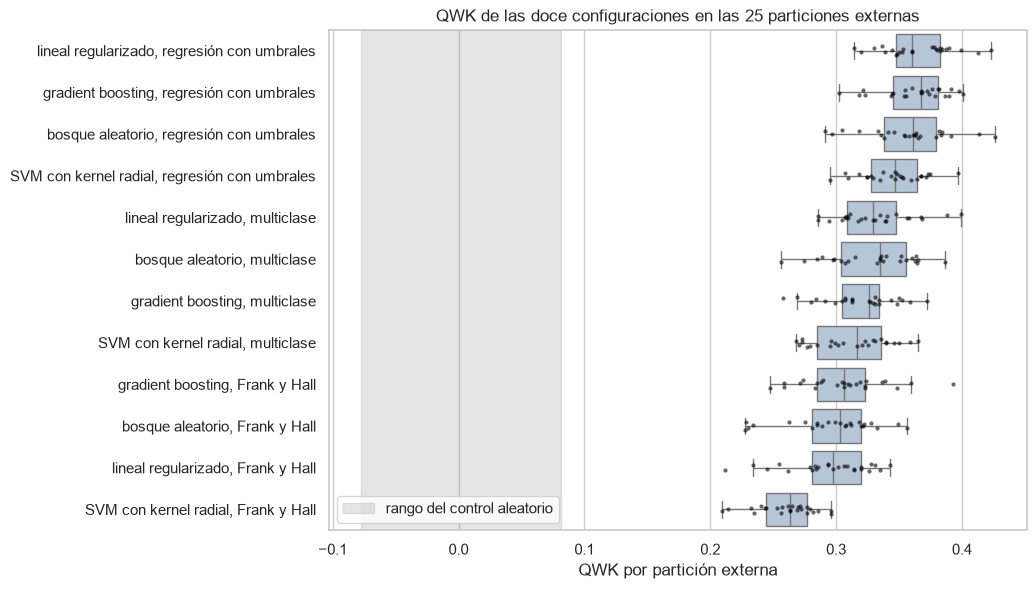

In [16]:
# QWK de cada partición externa por configuración, en el orden de la tabla anterior.
qwk_por_particion = pd.concat(
    [
        resultado.folds[["repeat", "fold", "qwk"]].assign(
            configuración=f"{NOMBRES_ALGORITMOS[a]}, {NOMBRES_FORMULACIONES[f]}"
        )
        for (a, f), resultado in resultados_e2.items()
    ],
    ignore_index=True,
)
orden = [f"{a}, {f}" for a, f in desempeno_e2.index]
qwk_aleatorio = resultados_controles["aleatorio estratificado"][0]["qwk"]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.axvspan(
    qwk_aleatorio.min(),
    qwk_aleatorio.max(),
    color="grey",
    alpha=0.2,
    label="rango del control aleatorio",
)
sns.boxplot(
    data=qwk_por_particion,
    x="qwk",
    y="configuración",
    order=orden,
    color="lightsteelblue",
    showfliers=False,
    ax=ax,
)
sns.stripplot(
    data=qwk_por_particion,
    x="qwk",
    y="configuración",
    order=orden,
    color="black",
    size=3,
    alpha=0.6,
    ax=ax,
)
ax.set(
    xlabel="QWK por partición externa",
    ylabel="",
    title="QWK de las doce configuraciones en las 25 particiones externas",
)
# La leyenda va sobre la franja del control, donde no hay cajas.
ax.legend(loc="lower left")
save_figure(fig, "qwk_por_configuracion", FIGURAS)
plt.show()

### Conclusión

- **Frente a los controles.** Las doce configuraciones aprenden de los predictores: el QWK más bajo de una partición en cualquier configuración (0,209) supera con amplitud el máximo del control aleatorio (0,082), cuyo QWK medio es prácticamente cero.
- **Formulación y algoritmo.** La formulación ordena el desempeño más que el algoritmo. Las cuatro regresiones con umbrales encabezan el QWK (0,345 a 0,365), seguidas de las configuraciones multiclase (0,312 a 0,331) y de Frank y Hall (0,260 a 0,307). Dentro de cada formulación, los algoritmos están a 0,02 o menos entre sí, salvo la SVM con Frank y Hall.
- **Variabilidad.** La desviación del QWK entre repeticiones es pequeña (0,015 como máximo), pero de una partición a otra el QWK de una misma configuración varía en unos 0,1. Las diferencias entre configuraciones son del orden de esa variación, así que compararlas exige la prueba pareada de la regla de selección, no solo las medias.
- **QWK frente a los niveles altos.** El QWK y la detección de los niveles altos van en direcciones opuestas. Las regresiones con umbrales tienen el mayor QWK, pero casi nunca asignan el nivel severo (recall severo de 0,041 como máximo) y subestiman cerca de dos tercios de los participantes moderados o severos. Las configuraciones de Frank y Hall detectan entre el 37 % y el 87 % de los severos y tienen la menor tasa de subestimación (0,35 a 0,47), a costa de casi no asignar el nivel leve. Las multiclase quedan en un punto intermedio. Como el QWK pondera cada participante por igual y los severos son el 1,2 % de la muestra, acertar en los niveles frecuentes pesa mucho más en la métrica que detectar a los severos.
- **Convergencia.** En las 25 particiones, la proporción de ajustes sin convergencia del modelo lineal es la misma que en la primera repetición (44,4 % en la formulación multiclase y 17,7 % en Frank y Hall). Las advertencias del imputador son escasas frente al número de ajustes.

La sección 5 revisa los hiperparámetros elegidos en cada partición, incluidos los que caen en los bordes de las grillas, y la sección 6 aplica la regla de selección.

## 5. Hiperparámetros elegidos y revisión de los bordes

En cada partición externa, la validación interna elige la estrategia de faltantes, el exponente de la ponderación y los hiperparámetros del modelo. Esta sección resume esas elecciones y aplica la regla de bordes de la sección 2, que usa solo los hiperparámetros elegidos y nunca el QWK de las particiones externas.

La regla se aplica así:

- *Hiperparámetros revisados:* los numéricos con al menos tres valores en su grilla. Con dos valores, como el exponente $\alpha$, la tasa de aprendizaje de gradient boosting o el `epsilon` de la SVR, cualquier elección es un extremo y no indica que el óptimo esté fuera de la grilla. La estrategia de faltantes es categórica.
- *Paso de la ampliación:* repite la razón entre los dos valores más cercanos al borde, porque las grillas son geométricas; por ejemplo, `C` pasa de 100 a 1.000. Los hiperparámetros enteros siguen siendo enteros.
- *Límites naturales:* un borde que coincide con el límite del hiperparámetro no se amplía. Es el caso de `l1_ratio` en 0 o 1 (ridge o lasso), `max_features` igual a 1 (todas las variables), `min_samples_leaf` igual a 1 y `l2_regularization` igual a 0.
- *Grilla revisada:* la que usó cada configuración en la búsqueda completa, después del nivel de recorte.

Las configuraciones que la regla amplía se repiten una sola vez con la grilla ampliada, y sus resultados se guardan aparte de los de la búsqueda completa.

In [17]:
def etiqueta_configuracion(configuracion: tuple[str, str]) -> tuple[str, str]:
    """Nombres en español de una configuración, para los índices de las tablas."""
    algoritmo, formulacion = configuracion
    return NOMBRES_ALGORITMOS[algoritmo], NOMBRES_FORMULACIONES[formulacion]


# Hiperparámetros elegidos por la validación interna en cada partición externa.
elegidos = {c: list(r.folds["best_params"]) for c, r in resultados_e2.items()}

# Estrategia de faltantes y exponente de la ponderación: particiones, de las 25,
# en las que la validación interna eligió cada valor.
filas = []
for configuracion, parametros in elegidos.items():
    estrategias = chosen_value_counts(parametros, "preprocess__strategy")
    exponentes = chosen_value_counts(parametros, "model__weight_power")
    filas.append(
        {
            **{
                f"estrategia {NOMBRES_ESTRATEGIAS[e]}": int(estrategias.get(e, 0))
                for e in NOMBRES_ESTRATEGIAS
            },
            **{f"α = {a:g}": int(exponentes.get(a, 0)) for a in (0.5, 1.0)},
        }
    )
tratamiento_elegido = pd.DataFrame(
    filas,
    index=pd.MultiIndex.from_tuples(
        [etiqueta_configuracion(c) for c in elegidos], names=["algoritmo", "formulación"]
    ),
)
tratamiento_elegido

estrategia nativa  \
algoritmo             formulación                                 
lineal regularizado   multiclase                              0   
                      Frank y Hall                            0   
gradient boosting     regresión con umbrales                  4   
                      Frank y Hall                            8   
                      multiclase                              5   
SVM con kernel radial regresión con umbrales                  0   
                      Frank y Hall                            0   
                      multiclase                              0   
lineal regularizado   regresión con umbrales                  0   
bosque aleatorio      regresión con umbrales                  0   
                      Frank y Hall                            0   
                      multiclase                              0   

                                              estrategia simple con indicadores  \
algoritmo             formulación                                                 
lineal regularizado   multiclase                                             20   
                      Frank y Hall                                           18   
gradient boosting     regresión con umbrales                                 11   
                      Frank y Hall                                            8   
                      multiclase                                              5   
SVM con kernel radial regresión con umbrales                                  5   
                      Frank y Hall                                           16   
                      multiclase                                              8   
lineal regularizado   regresión con umbrales                                  5   
bosque aleatorio      regresión con umbrales                                  7   
                      Frank y Hall                                           12   
                      multiclase                                              7   

                                              estrategia iterativa  α = 0.5  \
algoritmo             formulación                                             
lineal regularizado   multiclase                                 5       25   
                      Frank y Hall                               7        6   
gradient boosting     regresión con umbrales                    10       23   
                      Frank y Hall                               9        4   
                      multiclase                                15       18   
SVM con kernel radial regresión con umbrales                    20        0   
                      Frank y Hall                               9        0   
                      multiclase                                17        0   
lineal regularizado   regresión con umbrales                    20       25   
bosque aleatorio      regresión con umbrales                    18       18   
                      Frank y Hall                              13        0   
                      multiclase                                18        7   

                                              α = 1  
algoritmo             formulación                    
lineal regularizado   multiclase                  0  
                      Frank y Hall               19  
gradient boosting     regresión con umbrales      2  
                      Frank y Hall               21  
                      multiclase                  7  
SVM con kernel radial regresión con umbrales     25  
                      Frank y Hall               25  
                      multiclase                 25  
lineal regularizado   regresión con umbrales      0  
bosque aleatorio      regresión con umbrales      7  
                      Frank y Hall               25  
                      multiclase                 18

In [18]:
# Regla de bordes sobre la grilla con la que se ejecutó cada configuración.
revisiones = []
for configuracion, parametros in elegidos.items():
    grilla = tareas_e2[configuracion].estimator.param_grid
    revision = edge_review(parametros, grilla)
    revisiones.append(
        revision.assign(
            algoritmo=NOMBRES_ALGORITMOS[configuracion[0]],
            formulación=NOMBRES_FORMULACIONES[configuracion[1]],
            hiperparámetro=revision["parameter"].map(parameter_short_name),
        )
    )
revision_bordes = (
    pd.concat(revisiones, ignore_index=True)
    .rename(
        columns={
            "edge": "borde",
            "edge_value": "valor del borde",
            "folds_at_edge": "particiones en el borde",
            "extension_value": "valor de la ampliación",
            "extend": "se amplía",
        }
    )
    .replace({"borde": {"lower": "inferior", "upper": "superior"}})
    .set_index(["algoritmo", "formulación", "hiperparámetro", "borde"])
)[["valor del borde", "particiones en el borde", "valor de la ampliación", "se amplía"]]

# Ampliaciones que exige la regla, por configuración.
AMPLIACIONES = {
    configuracion: grid_extension(revision)
    for configuracion, revision in zip(elegidos, revisiones, strict=True)
    if grid_extension(revision)
}
print(
    f"Bordes revisados: {len(revision_bordes)}; elegidos en al menos "
    f"{EDGE_RULE_MIN_FOLDS} particiones: "
    f"{int((revision_bordes['particiones en el borde'] >= EDGE_RULE_MIN_FOLDS).sum())}; "
    f"se amplían: {int(revision_bordes['se amplía'].sum())}"
)
for configuracion, ampliacion in AMPLIACIONES.items():
    valores = "; ".join(
        f"{parameter_short_name(p)}: {', '.join(f'{v:g}' for v in vs)}"
        for p, vs in ampliacion.items()
    )
    print(f"Se amplía {', '.join(etiqueta_configuracion(configuracion))}: {valores}")
# Solo se muestran los bordes elegidos en al menos una partición.
revision_bordes[revision_bordes["particiones en el borde"] > 0]

Bordes revisados: 48; elegidos en al menos 5 particiones: 25; se amplían: 16
Se amplía lineal regularizado, Frank y Hall: C: 1000
Se amplía gradient boosting, regresión con umbrales: max_leaf_nodes: 3; min_samples_leaf: 3, 213; l2_regularization: 100
Se amplía gradient boosting, Frank y Hall: max_leaf_nodes: 3; min_samples_leaf: 3; l2_regularization: 100
Se amplía gradient boosting, multiclase: max_leaf_nodes: 3; min_samples_leaf: 3, 213; l2_regularization: 100
Se amplía SVM con kernel radial, regresión con umbrales: gamma: 1e-05
Se amplía SVM con kernel radial, Frank y Hall: gamma: 1e-05
Se amplía bosque aleatorio, regresión con umbrales: min_samples_leaf: 125
Se amplía bosque aleatorio, multiclase: min_samples_leaf: 125


valor del borde  \
algoritmo             formulación            hiperparámetro    borde                      
lineal regularizado   multiclase             C                 superior           100.0   
                                             l1_ratio          inferior             0.0   
                                                               superior             1.0   
                      Frank y Hall           C                 superior           100.0   
                                             l1_ratio          inferior             0.0   
                                                               superior             1.0   
gradient boosting     regresión con umbrales max_leaf_nodes    inferior               7   
                                             min_samples_leaf  inferior              10   
                                                               superior              80   
                                             l2_regularization inferior             0.0   
                                                               superior            10.0   
                      Frank y Hall           max_leaf_nodes    inferior               7   
                                                               superior              31   
                                             min_samples_leaf  inferior              10   
                                                               superior              80   
                                             l2_regularization inferior             0.0   
                                                               superior            10.0   
                      multiclase             max_leaf_nodes    inferior               7   
                                                               superior              31   
                                             min_samples_leaf  inferior              10   
                                                               superior              80   
                                             l2_regularization inferior             0.0   
                                                               superior            10.0   
SVM con kernel radial regresión con umbrales C                 superior          1000.0   
                                             gamma             inferior          0.0001   
                      Frank y Hall           C                 superior          1000.0   
                                             gamma             inferior          0.0001   
lineal regularizado   regresión con umbrales l1_ratio          inferior             0.0   
                                                               superior             1.0   
bosque aleatorio      regresión con umbrales min_samples_leaf  superior              50   
                      multiclase             min_samples_leaf  inferior               1   
                                                               superior              50   

                                                                         particiones en el borde  \
algoritmo             formulación            hiperparámetro    borde                               
lineal regularizado   multiclase             C                 superior                        2   
                                             l1_ratio          inferior                       10   
                                                               superior                        7   
                      Frank y Hall           C                 superior                        8   
                                             l1_ratio          inferior                        5   
                                                               superior                       15   
gradient boosting     regresión con umbrales max_leaf_nodes    inferior                       22   
                                             min_samples_leaf  inferior      